# ENCH 470 Fall 2021 Lecture 21: Machine learning in cheminformatics

Original notebook by Andrea Volkamer, https://github.com/volkamerlab/TeachOpenCADD

## Imports 

In [1]:
import pandas as pd
import numpy as np
import rdkit
from rdkit import Chem
from rdkit.Chem import Descriptors
from rdkit.Chem import rdFingerprintGenerator

import matplotlib.pyplot as plt

## Introduction to Classification

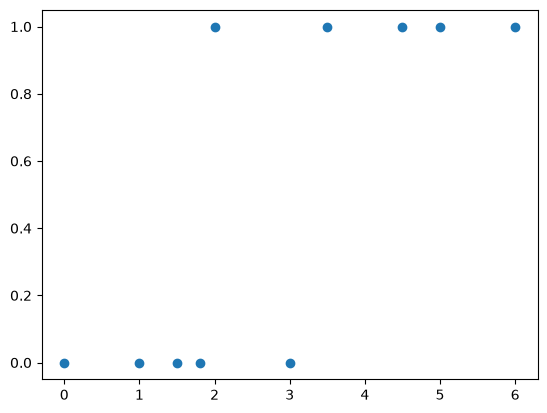

In [2]:
ym = np.array([0, 0, 0, 0, 1, 0, 1, 1, 1, 1])
xm = np.array([0, 1, 1.5, 1.8, 2, 3, 3.5, 4.5, 5, 6])

plt.scatter(xm,ym)

In [3]:
import sklearn
from sklearn.linear_model import LogisticRegression

In [4]:
print(xm)
xm = xm.reshape(-1,1)
print(xm)

[0.  1.  1.5 1.8 2.  3.  3.5 4.5 5.  6. ]
[[0. ]
 [1. ]
 [1.5]
 [1.8]
 [2. ]
 [3. ]
 [3.5]
 [4.5]
 [5. ]
 [6. ]]


In [5]:
# Create the classifier object
clf = LogisticRegression(random_state=0)

# Fit the classifier object
clf.fit(xm,ym)

# Inspect the parameters
print("The parameters are: ",clf.coef_)

# Check out the class predictions
ym_pred = clf.predict(xm)
#print(ym_pred)

# Check out the probability predictions
ym_prob = clf.predict_proba(xm)
#print(ym_prob)

# Calculate the classification score
score = clf.score(xm,ym)
print('The score is', score)

The parameters are:  [[1.04313016]]
The score is 0.8


**<font color=red> Problem: </font>** Plot the predictions of the classification model in high resolution! Show in a single figure:

1) the data (xm,ym) as points

2) a line for the predicted class from the model for x going from 0 to 6 in increments of 0.01

3) a line for the probability of class assignment for x going from 0 to 6 in increments of 0.01

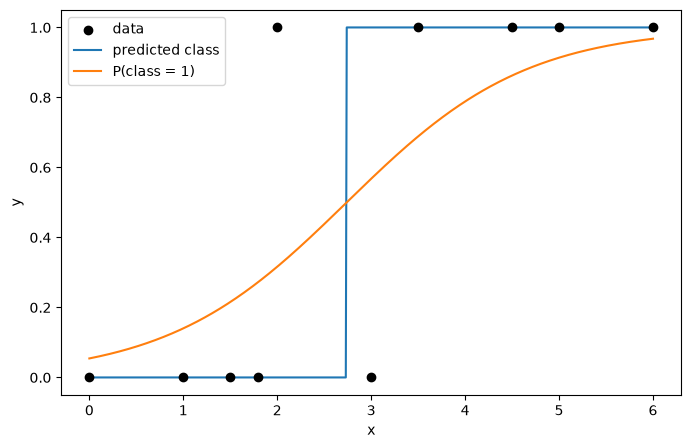

In [6]:
# x from 0 to 6 in steps of 0.01 (as a column, like xm)
x_fine = np.arange(0, 6.01, 0.01).reshape(-1,1)

y_fine_pred = clf.predict(x_fine)            # predicted class (0 or 1)
y_fine_prob = clf.predict_proba(x_fine)[:,1] # probability of class 1

fig,ax = plt.subplots(figsize=(8,5))
ax.scatter(xm, ym, color='k', zorder=3, label='data')
ax.plot(x_fine, y_fine_pred, label='predicted class')
ax.plot(x_fine, y_fine_prob, label='P(class = 1)')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.legend()

**<font color=orange> Extra Credit Problem: </font>** We can look up the fitted coefficients in the model using `clf.coef_`. Can you use that parameter in a logistic function to reproduce any of the curves above?

w = 1.0431301595832216  b = -2.856860672784853
Max difference from predict_proba: 0.0
Classes match predict: True


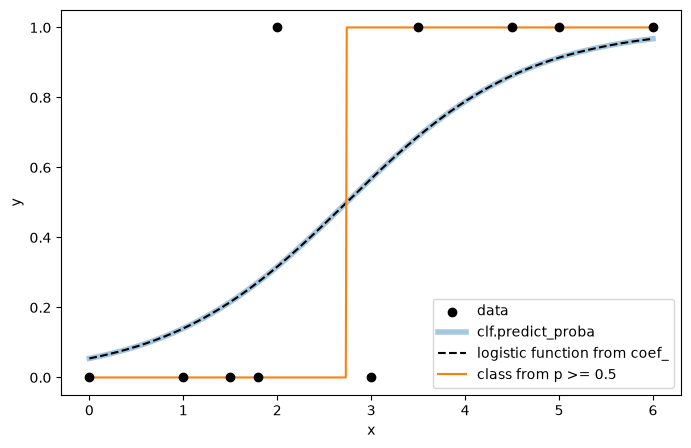

In [7]:
# Logistic function: p = 1 / (1 + exp(-(w*x + b)))
w = clf.coef_[0,0]
b = clf.intercept_[0]
print('w =', w, ' b =', b)

p_manual = 1/(1 + np.exp(-(w*x_fine + b)))

# The class is 1 wherever p >= 0.5
class_manual = (p_manual >= 0.5).astype(int)

print('Max difference from predict_proba:', np.max(np.abs(p_manual.ravel() - y_fine_prob)))
print('Classes match predict:', np.all(class_manual.ravel() == y_fine_pred))

fig,ax = plt.subplots(figsize=(8,5))
ax.scatter(xm, ym, color='k', zorder=3, label='data')
ax.plot(x_fine, y_fine_prob, lw=4, alpha=0.4, label='clf.predict_proba')
ax.plot(x_fine, p_manual, 'k--', label='logistic function from coef_')
ax.plot(x_fine, class_manual, label='class from p >= 0.5')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.legend()

## Classification of EGFR Inhibitors
### ChEMBL

* Largest freely available source for molecules and affinities
* https://www.ebi.ac.uk/chembl/

### EGFR - Epidermal Growth Factor Receptor

We're going to work with molecules developed to target the EGFR: https://en.wikipedia.org/wiki/Epidermal_growth_factor_receptor

#### Import the data for active and inactive molecules into dataframes

In [8]:
df_act = pd.read_csv('Chembl_EGFR_actives_ML.csv', delimiter=',', header=0)
df_inact = pd.read_csv('Chembl_EGFR_inactives_ML.csv', delimiter=',', header=0)

In [9]:
print (len(df_act), len(df_inact))

100 100


In [10]:
df_act.head(10)

,canonical_smiles,molecule_chembl_id
0,COc1ccc(NC(=O)c2ccc(cc2)N(CCCl)CCCl)cc1,CHEMBL589588
1,N(c1ccc2[nH]ccc2c1)c3ncnc4cc(sc34)c5ccccc5,CHEMBL76432
2,CS(=O)(=O)CCNCCCCOc1ccc2ncnc(Nc3ccc(F)c(Cl)c3)...,CHEMBL460731
3,NC(=O)C1CCN(Cc2ccc(cc2)c3cc4nccc(Nc5ccc6[nH]cc...,CHEMBL431977
4,CC(C)(CO)NCc1ccc(cc1)c2cc3ncnc(Nc4ccc5[nH]ccc5...,CHEMBL308498
5,Brc1cccc(Nc2ncnc3cnc(cc23)S(=O)(=O)C=C)c1,CHEMBL336264
6,CCN(CC)CC(O)CNc1cc2c(Nc3cccc(Br)c3)ncnc2cn1,CHEMBL433520
7,CN(C)CCCOC(=O)\C=C\C(=O)Nc1ccc2ncnc(Nc3cccc(Br...,CHEMBL140561
8,CN(C)CCCNC(=O)\C=C\C(=O)N(C)c1cc2c(Nc3cccc(Br)...,CHEMBL136102
9,Cc1cc(C)c(\C=C\2/C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4...,CHEMBL68920


#### Get SMILES in list

In [11]:
act_smiles = df_act['canonical_smiles'].tolist()
inact_smiles = df_inact['canonical_smiles'].tolist()

#### Make lists of molecule objects

In [12]:
#mols_act = []
#for i in act_smiles:
#    mols_act += [Chem.MolFromSmiles(i)]

# new_list = [operation or function on x for x in old_list ]

mols_act = [Chem.MolFromSmiles(i) for i in act_smiles]
mols_inact = [Chem.MolFromSmiles(i) for i in inact_smiles]

## Visualizing the data

Let's see what we got here in this dataset! Remember those descriptors we calculated last time? Let's get those, and add them to our dataframes

In [13]:
HeavyAtomCount_act = [Descriptors.HeavyAtomCount(x) for x in mols_act]
HeavyAtomCount_inact = [Descriptors.HeavyAtomCount(x) for x in mols_inact]

MolLogP_act = [Descriptors.MolLogP(x) for x in mols_act]
MolLogP_inact = [Descriptors.MolLogP(x) for x in mols_inact]

df_act['HeavyAtomCount'] = HeavyAtomCount_act
df_inact['HeavyAtomCount'] = HeavyAtomCount_inact

df_act['MolLogP'] = MolLogP_act
df_inact['MolLogP'] = MolLogP_inact

#df_act.head(10)

**<font color=red> Problem: </font>** Look up 3 more descriptors available under the `Descriptors` library in RDKit, and add them to the dataframes. You can find a list of these on [this page](https://www.rdkit.org/docs/GettingStartedInPython.html).

In [14]:
# Molecular weight, topological polar surface area, and number of H-bond donors
for name in ['MolWt', 'TPSA', 'NumHDonors']:
    descriptor = getattr(Descriptors, name)
    df_act[name] = [descriptor(x) for x in mols_act]
    df_inact[name] = [descriptor(x) for x in mols_inact]

df_act.head()

,canonical_smiles,molecule_chembl_id,HeavyAtomCount,MolLogP,MolWt,TPSA,NumHDonors
0,COc1ccc(NC(=O)c2ccc(cc2)N(CCCl)CCCl)cc1,CHEMBL589588,24,4.2315,367.276,41.57,1
1,N(c1ccc2[nH]ccc2c1)c3ncnc4cc(sc34)c5ccccc5,CHEMBL76432,25,5.5832,342.427,53.60,2
2,CS(=O)(=O)CCNCCCCOc1ccc2ncnc(Nc3ccc(F)c(Cl)c3)...,CHEMBL460731,31,3.9591,466.966,93.21,2
3,NC(=O)C1CCN(Cc2ccc(cc2)c3cc4nccc(Nc5ccc6[nH]cc...,CHEMBL431977,35,5.8855,481.625,87.04,3
4,CC(C)(CO)NCc1ccc(cc1)c2cc3ncnc(Nc4ccc5[nH]ccc5...,CHEMBL308498,32,5.4437,443.576,85.86,4


Let's visualize some of these properties

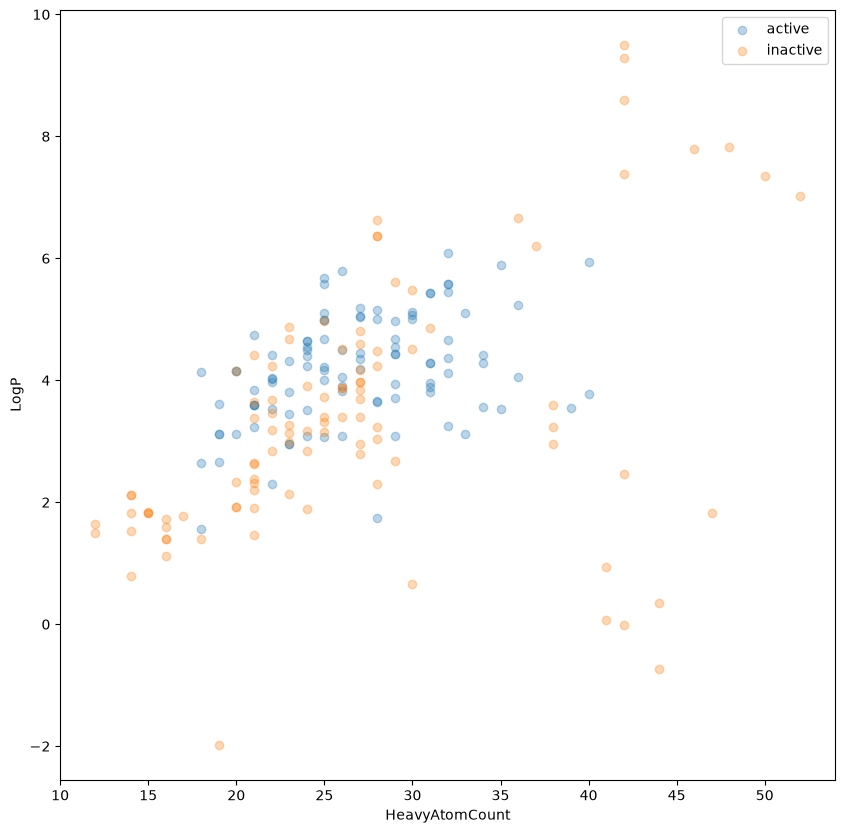

In [15]:
fig,ax = plt.subplots(figsize=(10,10))

ax.scatter(df_act['HeavyAtomCount'],df_act['MolLogP'],alpha=0.3)
ax.scatter(df_inact['HeavyAtomCount'],df_inact['MolLogP'],alpha=0.3)
ax.set_ylabel('LogP')
ax.set_xlabel('HeavyAtomCount')
ax.legend(['active','inactive'])

Text(0, 0.5, 'Number of molecules')

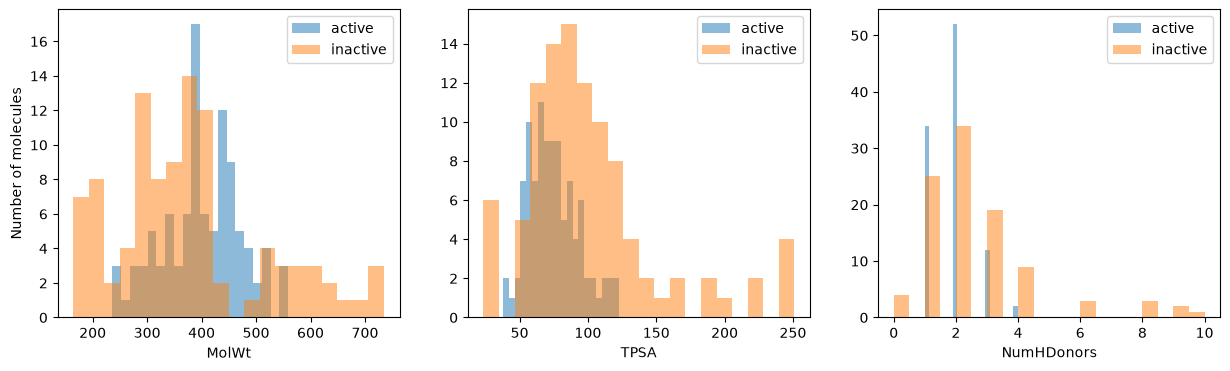

In [16]:
# Compare the distributions of the new descriptors for actives and inactives
fig,axes = plt.subplots(1, 3, figsize=(15,4))

for ax,name in zip(axes, ['MolWt', 'TPSA', 'NumHDonors']):
    ax.hist(df_act[name], bins=20, alpha=0.5, label='active')
    ax.hist(df_inact[name], bins=20, alpha=0.5, label='inactive')
    ax.set_xlabel(name)
    ax.legend()

axes[0].set_ylabel('Number of molecules')

#### Calculate fingerprints

By default the RDKit generates Morgan fingerprints with radius 2 (MFP2)

In [17]:
# Fingerprints for active molecules
fps_act = rdFingerprintGenerator.GetFPs(mols_act)

# Fingerprints for inactive molecules
fps_inact = rdFingerprintGenerator.GetFPs(mols_inact)

# Concatenate fingerprints
fps = fps_act + fps_inact

#### Assign classes to each molecule

In [18]:
# 'Active' = 1
y_act = np.ones(len(fps_act))

# 'Inactive' = 0
y_inact = np.zeros(len(fps_inact))

# Classifier
y = np.concatenate([y_act, y_inact])

## Logistic regression on EGFR dataset

Now, **using the fingerprints as our features** let's fit a logistic regression model!


### Split data in train and test set

In [19]:
from sklearn.model_selection import train_test_split

# 20% for testing, 80% for training
X_train, X_test, y_train, y_test = train_test_split(fps, y, test_size=0.20, random_state=0)

### Train the model


In [20]:
clf = LogisticRegression(random_state=0).fit(X_train,y_train)

print("The parameters are: ", clf.coef_)

#for i in range(len(clf.coef_[0])):
#    print(i, clf.coef_[0,i])

#plt.scatter(np.arange(0,2048),clf.coef_)

#print(y_train)

y_train_pred = clf.predict(X_train)
print(y_train_pred)

y_train_prob = clf.predict_proba(X_train)

score = clf.score(X_train,y_train)
print(score)

The parameters are:  [[ 0.         -0.06454704  0.00053888 ...  0.01578978  0.01928318
  -0.08042276]]
[0. 1. 1. 0. 0. 1. 1. 1. 0. 0. 1. 0. 0. 1. 0. 1. 1. 0. 1. 1. 0. 1. 0. 1.
 0. 1. 1. 0. 1. 1. 0. 1. 0. 0. 0. 1. 0. 1. 1. 0. 0. 1. 0. 0. 0. 1. 1. 1.
 0. 0. 1. 1. 0. 1. 0. 0. 0. 0. 1. 0. 0. 0. 1. 1. 1. 0. 1. 1. 0. 1. 1. 1.
 1. 1. 1. 0. 1. 0. 0. 1. 1. 1. 0. 1. 0. 1. 1. 0. 0. 0. 1. 1. 1. 0. 0. 0.
 0. 1. 0. 1. 0. 0. 1. 1. 1. 1. 0. 0. 1. 0. 0. 0. 1. 1. 0. 1. 0. 0. 1. 1.
 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 1. 1. 1. 1. 0. 0. 0. 1. 1. 1. 0. 1. 0. 0.
 0. 1. 1. 0. 1. 1. 1. 1. 1. 1. 0. 1. 0. 0. 1. 0.]


0.99375


### Test performance of the model

In [21]:
y_test_pred = clf.predict(X_test)
#print(y_test_pred)

y_test_prob = clf.predict_proba(X_test)
#print(y_test_prob)

score = clf.score(X_test,y_test)
print(score)


import sklearn.metrics as metrics
accuracy = metrics.accuracy_score(y_test,y_test_pred)
print(accuracy)

# The confusion matrix shows false positives and false negatives
print("Confusion matrix:")
print(metrics.confusion_matrix(y_test,y_test_pred))

0.925
0.925
Confusion matrix:
[[20  2]
 [ 1 17]]


## Logistic regression predictions for FDA approved drugs

In [22]:
df = pd.read_csv('EGFR-FDA.csv', delimiter=',', names=['Smiles', 'Name'], header=None)
df.head()

,Smiles,Name
0,COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCOCC1,Gefitinib
1,C#Cc1cccc(Nc2ncnc3cc(OCCOC)c(OCCOC)cc23)c1,Erlotinib
2,CS(=O)(=O)CCNCc1ccc(-c2ccc3ncnc(Nc4ccc(OCc5ccc...,Lapatinib
3,CN(C)C/C=C/C(=O)Nc1cc2c(Nc3ccc(F)c(Cl)c3)ncnc2...,Afatinib
4,C=CC(=O)Nc1cc(Nc2nccc(-c3cn(C)c4ccccc34)n2)c(O...,Osimertinib


In [23]:
for tmp_smiles in df.Smiles.values:
    mol = Chem.MolFromSmiles(tmp_smiles)
    fps = rdFingerprintGenerator.GetFPs([mol])
    
    y_pred = clf.predict(fps)
    y_prob = clf.predict_proba(fps)
    print(y_pred, y_prob)

[1.] [[0.0117136 0.9882864]]
[1.] [[0.00916079 0.99083921]]
[1.] [[0.00914367 0.99085633]]
[1.] [[0.00130837 0.99869163]]
[0.] [[0.86464523 0.13535477]]


**<font color=red> Problem: </font>** Plot training accuracy vs. training set size from 10% in training set to 100% in training set. Plot test accuracy vs. training set size from 10% in training set to 100% in training set.

   10%  train = 1.000  test = 0.850
   20%  train = 1.000  test = 0.850
   30%  train = 1.000  test = 0.900
   40%  train = 1.000  test = 0.850
   50%  train = 1.000  test = 0.825
   60%  train = 1.000  test = 0.925
   70%  train = 1.000  test = 0.925
   80%  train = 0.992  test = 0.925
   90%  train = 0.993  test = 0.925
  100%  train = 0.994  test = 0.925


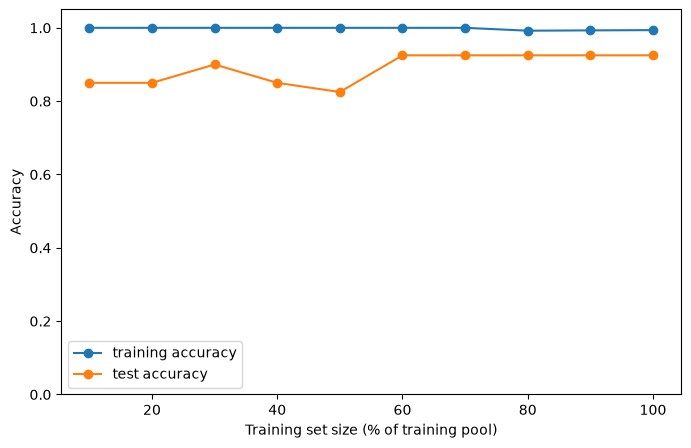

In [24]:
# Keep one fixed test set (20%), then train on 10%, 20%, ..., 100% of the training pool.
# (fps was reused for the FDA drugs above, so rebuild the full fingerprint list.)
fps_all = fps_act + fps_inact
X_pool, X_test_fixed, y_pool, y_test_fixed = train_test_split(fps_all, y, test_size=0.20, random_state=0)

fractions = np.arange(0.1, 1.01, 0.1)
train_acc = []
test_acc = []

for frac in fractions:
    n = int(round(frac*len(X_pool)))
    X_sub, y_sub = X_pool[:n], y_pool[:n]   # train_test_split already shuffled the pool

    clf_frac = LogisticRegression(random_state=0).fit(X_sub, y_sub)
    train_acc.append(clf_frac.score(X_sub, y_sub))
    test_acc.append(clf_frac.score(X_test_fixed, y_test_fixed))

fig,ax = plt.subplots(figsize=(8,5))
ax.plot(fractions*100, train_acc, 'o-', label='training accuracy')
ax.plot(fractions*100, test_acc, 'o-', label='test accuracy')
ax.set_xlabel('Training set size (% of training pool)')
ax.set_ylabel('Accuracy')
ax.set_ylim(0, 1.05)
ax.legend()

for frac,tr,te in zip(fractions, train_acc, test_acc):
    print(f'{frac*100:5.0f}%  train = {tr:.3f}  test = {te:.3f}')

**Findings:** Training accuracy stays at about 1.0 for every training set size: with 2048 fingerprint bits and at most 160 molecules, logistic regression can almost always separate the training set perfectly. Test accuracy climbs from about 0.85 with 10% of the training pool to about 0.93 from 60% onward, then levels off. The persistent gap between training and test accuracy is overfitting; more data helps until about 60%, after which this model and feature set stop improving.

**<font color=red> Problem: </font>** Examine the Tanimoto similarity of the active and inactive molecules to each of the 5 FDA-approved molecules using the Morgan fingerprints of radius 2. Think of a way to visualize this, and share your findings.

Gefitinib    actives: mean = 0.306, max = 1.000   inactives: mean = 0.111, max = 0.417
Erlotinib    actives: mean = 0.300, max = 0.536   inactives: mean = 0.119, max = 0.393
Lapatinib    actives: mean = 0.247, max = 0.489   inactives: mean = 0.107, max = 0.247
Afatinib     actives: mean = 0.274, max = 0.538   inactives: mean = 0.117, max = 0.316
Osimertinib  actives: mean = 0.167, max = 0.283   inactives: mean = 0.138, max = 0.323


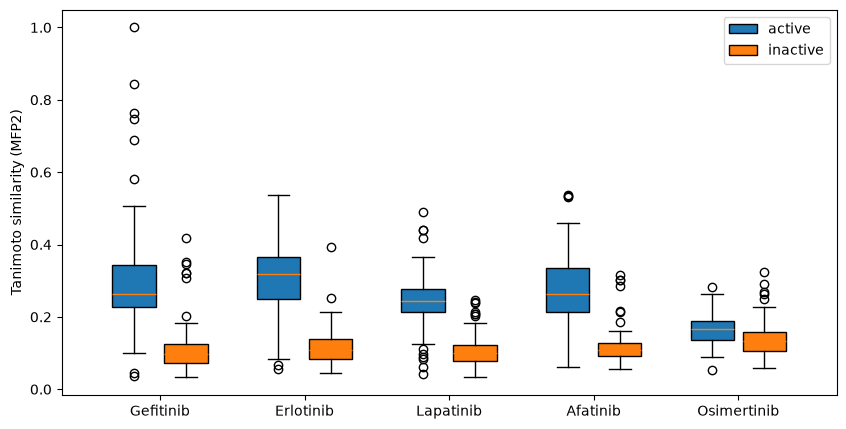

In [25]:
from rdkit import DataStructs

fda_names = df['Name'].tolist()
fda_fps = rdFingerprintGenerator.GetFPs([Chem.MolFromSmiles(s) for s in df['Smiles']])

# Similarity of every active and inactive molecule to each FDA drug
sim_act = [DataStructs.BulkTanimotoSimilarity(fp, fps_act) for fp in fda_fps]
sim_inact = [DataStructs.BulkTanimotoSimilarity(fp, fps_inact) for fp in fda_fps]

# Box plots: actives and inactives side by side for each drug
fig,ax = plt.subplots(figsize=(10,5))
pos = np.arange(len(fda_names))
b1 = ax.boxplot(sim_act, positions=pos-0.18, widths=0.3, patch_artist=True)
b2 = ax.boxplot(sim_inact, positions=pos+0.18, widths=0.3, patch_artist=True)
for patch in b1['boxes']: patch.set_facecolor('tab:blue')
for patch in b2['boxes']: patch.set_facecolor('tab:orange')
ax.set_xticks(pos)
ax.set_xticklabels(fda_names)
ax.set_ylabel('Tanimoto similarity (MFP2)')
ax.legend([b1['boxes'][0], b2['boxes'][0]], ['active', 'inactive'])

for name,sa,si in zip(fda_names, sim_act, sim_inact):
    print(f'{name:12s} actives: mean = {np.mean(sa):.3f}, max = {np.max(sa):.3f}   '
          f'inactives: mean = {np.mean(si):.3f}, max = {np.max(si):.3f}')

**Findings:** For Gefitinib, Erlotinib, Lapatinib and Afatinib, the actives are clearly more similar than the inactives (mean Tanimoto about 0.25–0.31 vs. about 0.11). These four drugs share the anilino-quinazoline core that many of the ChEMBL actives have, which is why the classifier calls all four active. Gefitinib has a similarity of 1.0 to one active, meaning Gefitinib itself is in the training data, so its prediction is not a fair test. Osimertinib is different: it is only weakly similar to both sets (mean 0.17 vs. 0.14, and its closest neighbor is an *inactive*). It is a third-generation, pyrimidine-based inhibitor that does not look like this older training data, which explains why the model predicts it as inactive even though it is an approved EGFR drug.

**<font color=orange> Extra credit: </font>** Take a look at the classification coefficients. Which molecular fingerprint features have the largest weights? For the top 10 features, find a molecule with that fragment, and visualize the fragment.

bit 1226: w = +0.77 (75 act / 1 inact)
bit 1367: w = +0.58 (84 act / 4 inact)
bit 843: w = +0.57 (41 act / 10 inact)
bit 27: w = +0.57 (2 act / 0 inact)
bit 1097: w = +0.55 (75 act / 7 inact)
bit 491: w = +0.55 (90 act / 16 inact)
bit 708: w = +0.54 (85 act / 6 inact)
bit 1347: w = +0.52 (2 act / 8 inact)
bit 1452: w = +0.50 (95 act / 24 inact)
bit 191: w = +0.48 (84 act / 29 inact)


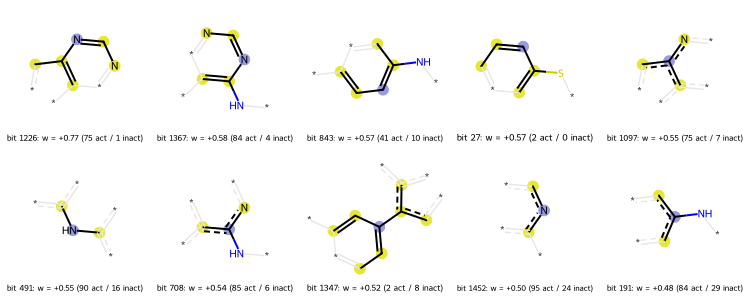

In [26]:
from rdkit.Chem import Draw

# clf is the fingerprint model trained above; each coefficient belongs to one fingerprint bit
coefs = clf.coef_[0]
top10 = np.argsort(np.abs(coefs))[::-1][:10]

# Same fingerprint as GetFPs (Morgan, radius 2, 2048 bits), but also returns which atoms set each bit
morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

def bit_info(mol):
    ao = rdFingerprintGenerator.AdditionalOutput()
    ao.AllocateBitInfoMap()
    morgan_gen.GetFingerprint(mol, additionalOutput=ao)
    return ao.GetBitInfoMap()

info_act = [bit_info(m) for m in mols_act]
info_inact = [bit_info(m) for m in mols_inact]

# For a positive weight look in the actives first, for a negative weight in the inactives first
fragments = []
legends = []
for bit in top10:
    w = coefs[bit]
    search = [(mols_act, info_act), (mols_inact, info_inact)]
    if w < 0:
        search.reverse()
    for mols, infos in search:
        hits = [k for k in range(len(mols)) if bit in infos[k]]
        if hits:
            k = hits[0]
            fragments.append((mols[k], int(bit), infos[k]))
            break
    n_act = sum(bit in d for d in info_act)
    n_inact = sum(bit in d for d in info_inact)
    legends.append(f'bit {bit}: w = {w:+.2f} ({n_act} act / {n_inact} inact)')
    print(legends[-1])

Draw.DrawMorganBits(fragments, molsPerRow=5, legends=legends)

**Findings:** The ten largest weights are all positive (they push a molecule toward *active*). Most of them are pieces of the anilino-pyrimidine/quinazoline scaffold: aromatic ring nitrogens (bits 1226, 1367, 1097, 708, 1452) and the aryl–NH–aryl linker (bits 843, 491, 191). Bit 1226 is the strongest and the most specific, appearing in 75 actives but only 1 inactive. A few top bits are rare (bit 27 appears in only 2 molecules; bit 1347 appears in more inactives than actives), so their large weights partly reflect the model fitting individual training molecules rather than general chemistry.